# 070 CASE 150 — Raw SAR floods: Örnsköldsvik 2025

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) on
> [rawsar](https://github.com/aidotse/ornskoldsvik-flood-sar-poc) by AI Sweden. Not a validated
> product or service, and without support.

**Question:** How well does Sentinel-1 radar change detection find the September 2025 flood in
Västernorrland, compared with the Copernicus EMS flood maps?

**Area:** The Gottne valley near Örnsköldsvik (Västernorrland), Copernicus EMS activation EMSR841,
area AOI01. Heavy rain on 6–7 September 2025 closed around 40 roads.

**Partners:** AI Sweden (rawsar), RISE

**Data:** Copernicus Sentinel-1 GRD from the [Copernicus Data Space Ecosystem](https://dataspace.copernicus.eu)
(Sentinel-1 is not yet on Digital Earth Sweden), the Copernicus GLO-30 elevation model and the
Copernicus EMS flood maps. Four scenes: before and during the flood on the two tracks whose EMS maps
were drawn from the same acquisition.

**Login:** the Sentinel-1 download needs your own free Copernicus Data Space account in `.env`
(`CDSE_USERNAME`, `CDSE_PASSWORD`); run `python scripts/fetch_all_data.py --config configs/case150_subset.yaml --yes`
once before this notebook. The elevation model and the EMS maps are public.

**Licence:** The notebook is Apache-2.0; its saved outputs are CC0 1.0. rawsar is MIT (see `LICENSE`);
its Level-0 decoder dependency, not used here, is GPL-3.0.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import yaml
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from rawsar import grd, flood

ROOT = Path("..").resolve()
cfg = yaml.safe_load(open(ROOT / "configs/case150_subset.yaml"))
BBOX = tuple(cfg["aoi"]["bbox"])
DEM = ROOT / "data/dem/aoi_glo30_utm33_20m.tif"
GTC_DIR = ROOT / "data/gtc"
EMS_DIR = ROOT / "data/ems"
plt.rcParams["figure.dpi"] = 110

## The four scenes

Two relative orbits, each with a scene before the flood and the scene that Copernicus EMS used for
its flood map: track 131 (ascending, evening) with the first estimate product (FEP) on 10 September,
and track 22 (descending, morning) with the second monitoring product (MONIT02) on 15 September.

In [2]:
prods = [p for p in grd.scan(ROOT / cfg["download"]["target_dir"]) if p.kind == "GRDH" and not p.is_cog]
pd.DataFrame([{"sensing": p.start, "satellite": p.platform, "relative orbit": p.relative_orbit,
               "pass": "ascending" if p.start.hour > 12 else "descending"} for p in prods]
             ).sort_values(["relative orbit", "sensing"]).reset_index(drop=True)

,sensing,satellite,relative orbit,pass
0,2025-09-03 05:06:02,S1A,22,descending
1,2025-09-15 05:06:02,S1A,22,descending
2,2025-09-04 16:13:26,S1C,131,ascending
3,2025-09-10 16:14:17,S1A,131,ascending


## Terrain-corrected backscatter

Each scene is geocoded to calibrated VV backscatter (σ⁰) on a 20 m grid with the GLO-30 elevation
model, using rawsar's wrapper around `sarsen`. Results are cached in `data/gtc/`; the first run takes
about a minute per scene.

In [3]:
dem_path = grd.prepare_dem(sorted((ROOT / "data/dem").glob("Copernicus_DSM_COG_10_N63_00_E01*_DEM.tif")), BBOX, DEM)
sigma0 = {}
for p in prods:
    out = GTC_DIR / f"{p.platform}_{p.relative_orbit:03d}_{p.start:%Y%m%d}_VV_sigma0.tif"
    sigma0[(p.relative_orbit, p.start.date())] = grd.gtc_sigma0(p, "VV", dem_path, out, crop_bbox=BBOX)
template = next(iter(sigma0.values()))
print(f"{len(sigma0)} scenes on a {template.shape[0]} × {template.shape[1]} grid (20 m)")

4 scenes on a 2041 × 2500 grid (20 m)


## Copernicus EMS flood maps

The reference is what each EMS product says was flooded: the observed flood, plus the cumulative
maximum extent where the product has one. Water that is dark already before the flood (rivers,
lakes) is removed from both detection and reference, so the scores measure the flood itself.

In [4]:
aoi = gpd.read_file(EMS_DIR / "EMSR841_AOI01_DEL_MONIT02_v1/EMSR841_AOI01_DEL_MONIT02_areaOfInterestA_v1.json")
aoi_mask = flood.rasterize_labels(aoi, template)


def ems_reference(folder, stem):
    obs = flood.rasterize_labels(gpd.read_file(EMS_DIR / folder / f"EMSR841_AOI01_{stem}_observedEventA_v1.json"), template)
    mfe = EMS_DIR / folder / f"EMSR841_AOI01_{stem}_maximumFloodExtentA_v1.json"
    return obs | flood.rasterize_labels(gpd.read_file(mfe), template) if mfe.exists() else obs


CASES = {  # track: (pre-flood date, label date, EMS folder, EMS stem, label)
    131: ("2025-09-04", "2025-09-10", "EMSR841_AOI01_FEP_PRODUCT_v1", "FEP_PRODUCT", "FEP, 10 Sept"),
    22:  ("2025-09-03", "2025-09-15", "EMSR841_AOI01_DEL_MONIT02_v1", "DEL_MONIT02", "MONIT02, 15 Sept"),
}
pre_131 = flood.to_db(sigma0[(131, pd.Timestamp("2025-09-04").date())]).where(aoi_mask)
perm_water, thr_pw = flood.water_mask_single(pre_131)
print(f"analysis area (EMS AOI): {float(aoi_mask.sum()) * 4e-4:.0f} km²; "
      f"water before the flood: {float(perm_water.sum()) * 4e-4:.1f} km² (threshold {thr_pw:.1f} dB)")

analysis area (EMS AOI): 57 km²; water before the flood: 18.4 km² (threshold -14.0 dB)


## Change detection against the EMS maps

For each track, the flood scene is compared with the scene before the flood: pixels whose backscatter
drops strongly (log-ratio below an Otsu threshold, capped at −3 dB) are flagged as new water. A
single-image dark-pixel mask is shown for comparison. Both are scored against the EMS map drawn from
the same acquisition, so the time offset is zero.

In [5]:
rows, maps = [], {}
for track, (pre, post, folder, stem, label) in CASES.items():
    db_pre = flood.to_db(sigma0[(track, pd.Timestamp(pre).date())]).where(aoi_mask)
    db_post = flood.to_db(sigma0[(track, pd.Timestamp(post).date())]).where(aoi_mask)
    truth = ems_reference(folder, stem) & ~perm_water
    valid = xr.apply_ufunc(np.isfinite, db_post) & xr.apply_ufunc(np.isfinite, db_pre) & aoi_mask
    change, thr_c = flood.water_mask_logratio(db_post, db_pre)
    dark, thr_d = flood.water_mask_single(db_post)
    for name, mask, thr in (("log-ratio change", change & ~perm_water, thr_c),
                            ("dark pixels", dark & ~perm_water, thr_d)):
        m = flood.iou_f1(mask, truth, valid=valid)
        rows.append({"track": track, "EMS map": label, "method": name, "threshold dB": round(thr, 1),
                     "EMS flood km²": round(m["truth_area_km2"], 2), "detected km²": round(m["pred_area_km2"], 2),
                     "IoU": round(m["iou"], 3), "F1": round(m["f1"], 3),
                     "recall": round(m["recall"], 2), "false alarms (share of dry area)": round(m["fpr"], 3)})
    maps[track] = (change & ~perm_water, truth, valid, label)
scores = pd.DataFrame(rows)
scores

,track,EMS map,method,threshold dB,EMS flood km²,detected km²,IoU,F1,recall,false alarms (share of dry area)
0,131,"FEP, 10 Sept",log-ratio change,-3.0,1.42,9.20,0.047,0.090,0.34,0.157
1,131,"FEP, 10 Sept",dark pixels,-14.0,1.42,5.85,0.062,0.117,0.30,0.098
2,22,"MONIT02, 15 Sept",log-ratio change,-3.0,0.80,4.73,0.027,0.053,0.18,0.082
3,22,"MONIT02, 15 Sept",dark pixels,-14.7,0.80,6.97,0.028,0.054,0.26,0.121


## Where the detection hits and misses (log-ratio change)

Top: the whole analysis area. Bottom: a 5 km × 5 km window where the EMS map shows the most flooding.
Grey is the analysis area without flood in either map.

Text(0.5, 0.98, 'Sentinel-1 log-ratio change detection vs Copernicus EMS, Gottne valley (north up)')

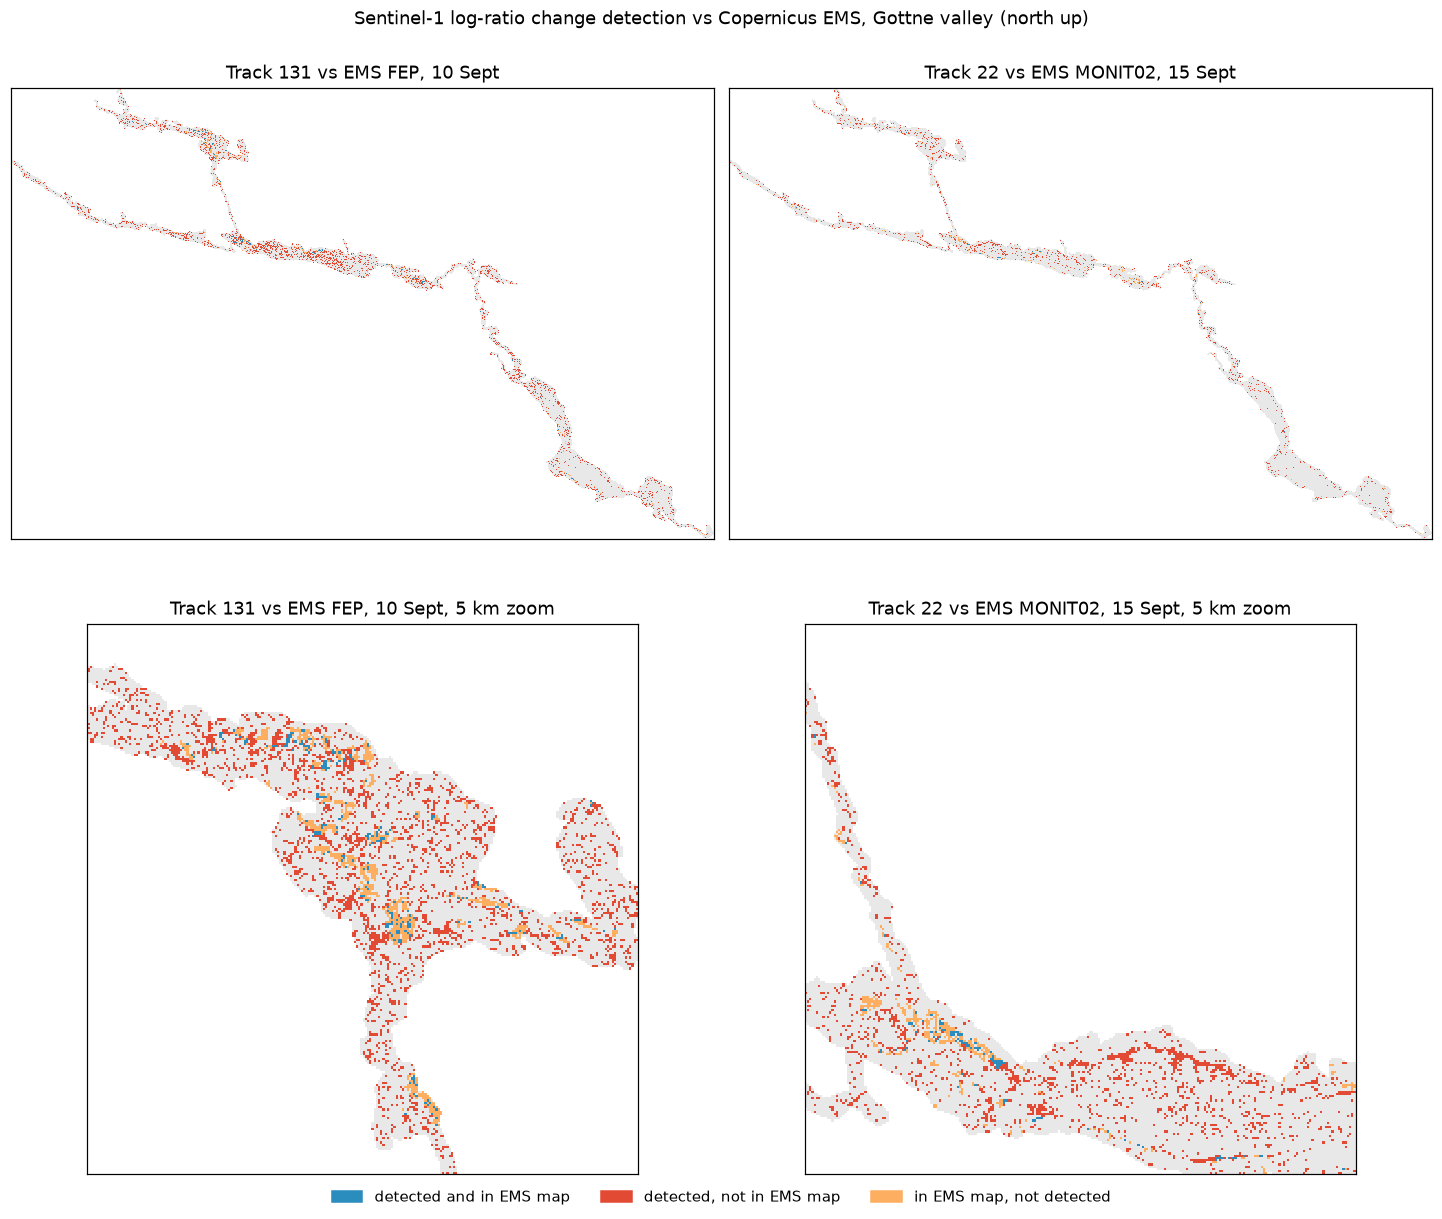

In [6]:
cmap = ListedColormap(["#ffffff", "#e8e8e8", "#2b8cbe", "#e34a33", "#fdae61"])  # outside, dry, hit, false alarm, missed
rows_aoi = np.where(np.asarray(aoi_mask.values).any(axis=1))[0]
cols_aoi = np.where(np.asarray(aoi_mask.values).any(axis=0))[0]
crop = (slice(rows_aoi[0], rows_aoi[-1] + 1), slice(cols_aoi[0], cols_aoi[-1] + 1))
flip = template.y.values[0] < template.y.values[-1]  # sarsen writes south-to-north; show north up
fig, axes = plt.subplots(2, 2, figsize=(13, 11), layout="constrained")
for col, (track, (pred, truth, valid, label)) in enumerate(maps.items()):
    p, t, v = (np.asarray(a.values, bool) for a in (pred, truth, valid))
    cls = np.where(v, 1, 0)
    cls[v & p & t] = 2
    cls[v & p & ~t] = 3
    cls[v & ~p & t] = 4
    zoom = flood.top_hotspot_windows(t, window=250, n=1)[0]  # 250 px = 5 km
    for row, sl in enumerate((crop, zoom)):
        img = cls[sl]
        ax = axes[row, col]
        ax.imshow(img[::-1] if flip else img, cmap=cmap, vmin=0, vmax=4, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"Track {track} vs EMS {label}" + ("" if row == 0 else ", 5 km zoom"))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors[2:]]
fig.legend(handles, ["detected and in EMS map", "detected, not in EMS map", "in EMS map, not detected"],
           loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("Sentinel-1 log-ratio change detection vs Copernicus EMS, Gottne valley (north up)")

## What this shows

- **Track 131, 10 September (EMS first estimate, same acquisition):** log-ratio change detection
  reaches IoU 0.047 and F1 0.090. It finds about a third of the flood in the EMS map (recall 0.34),
  but flags 9.2 km² as new water against 1.42 km² in the map, so false alarms cover about 16 % of the
  area that did not flood.
- **Track 22, 15 September (EMS monitoring product, same acquisition):** the scores are lower, IoU 0.027
  and F1 0.053, with recall 0.18. By then most of the standing water had receded; the map is mainly
  the maximum extent the flood reached.
- **A single dark-pixel threshold does no better** (IoU 0.062 and 0.028).
- **Why it is hard:** the flood is a thin strip along the valley floor, and about 18 km² of the
  57 km² area is already dark before the flood (rivers, lakes, radar shadow, wet fields) and is left
  out of the scoring. The remaining false alarms are scattered across the valley (map above). The
  pilot's own analysis found that despeckling, slope masking and adaptive thresholds did not improve
  on this baseline and that persistent dark surfaces cause most false alarms, which is why it goes on
  to the raw signal (Level-0) in the other notebooks of this repository.
- These numbers reproduce the pilot's own baseline (IoU 0.047, F1 0.089 against the first estimate)
  and are the level any new method has to beat.